# Eras Tour replay: predicting outfits and surprise songs

Swift Alert's **Mastermind** game asks, before every Eras Tour show, which version of each outfit Taylor Swift will
wear and which surprise songs she will play. 15 picks, 4 points each; the surprise songs are one guess per
instrument (guitar, piano), 2 points each.

This notebook replays the whole tour: for every show, each method predicts from **the earlier shows only**, then
gets scored against what actually happened.

- **Prophet**: the method from my [original Medium experiment](https://medium.com/@sparklingdust/beating-my-own-self-on-swift-alert-mastermind-game-in-guessing-taylor-swift-eras-tour-outfit-52b6535e0d8f). One worn / not worn series per version, forecast for the show's date. Two variants: with the night number in the city (1, 2, 3...) as an extra regressor, and **improved**, with what the earlier shows say about each version (worn at the previous show, earlier in this city, shows since last worn, share of the last 10) as regressors. The forecasts, normalised over the versions, give a probability.
- **Choice model**: a conditional logit. Each candidate version gets features (overall / recent / this-leg share, shows since last worn, earlier in the same city, ...). The weights are learned from all earlier shows and shared across categories, plus a small per-category adjustment.
- **Baselines**: worn most overall, worn most in the last 10 shows, rotation.

Data: the fan-made Eras Tour tracker sheet (outfits + surprise songs), downloaded below. It is not stored in this repo.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

from eras import backtest as B, data, lookup
from eras.paths import ARTIFACTS_DIR, DATA_DIR, RESULTS_DIR

PROPHET = True        # the article's method and 2 variants: ~8 minutes on 8 cores (pip install "eras[prophet]"); False skips it

if not (DATA_DIR / "outfits.csv").exists():
    data.download(DATA_DIR)
tour = data.load(DATA_DIR)
print(f"{tour.n} shows, {tour.shows.date.min():%d %b %Y} - {tour.shows.date.max():%d %b %Y}")

149 shows, 17 Mar 2023 - 08 Dec 2024


## The data

In [2]:
tour.shows.groupby("leg", sort=False).size().rename("shows").to_frame()

,shows
leg,
U.S. 2023,53
Latin America 2023,13
Asia & Australia 2024,17
Europe 2024,48
North America 2024,18


In [3]:
versions = pd.DataFrame([{"category": c, "versions": len({w for w in tour.outfits[c] if w}),
                          "shows": sum(w is not None for w in tour.outfits[c])}
                         for c in data.OUTFIT_CATEGORIES]).set_index("category")
versions

,versions,shows
category,,
Lover bodysuit,5,149
The Man jacket,5,149
Fearless dress,6,149
Red shirt,6,149
Speak Now dress,9,149
Reputation outfit,2,149
Folkmore dress,7,149
1989 set,38,149
TTPD outfit,12,65


In [4]:
# how often each version was worn, e.g. the 1989 set (the hardest category: many colours)
pd.Series([w for w in tour.outfits["1989 set"] if w]).value_counts().head(15)

Pink               29
Orange             24
GREEEEEEEEEEN      21
Blue                9
Yellow / Pink       5
Yellow / Orange     5
Blue / Orange       4
Blue / Purple       3
Purple / Yellow     3
Orange / Purple     3
Green / Blue        3
Pink / Pink         2
Orange / Green      2
Purple / Pink       2
Green / Orange      2
Name: count, dtype: int64

In [5]:
songs = pd.Series([s for show in tour.guitar + tour.piano for s in show])
print(f"{songs.nunique()} different surprise songs, {len(songs)} plays; most played:")
songs.value_counts().head(10)

194 different surprise songs, 447 plays; most played:


You're On Your Own, Kid     11
Maroon                      10
Out Of The Woods             7
Death By A Thousand Cuts     6
Clean                        6
Is It Over Now?              5
Haunted                      5
exile                        5
Red                          5
Getaway Car                  5
Name: count, dtype: int64

## Replay the tour

In [6]:
results = B.run(tour, warmup=10, prophet=PROPHET, progress=print)
results.head()

outfits: show 25/148


outfits: show 50/148


outfits: show 75/148


outfits: show 100/148


outfits: show 125/148


...

songs: show 50/148


songs: show 75/148


songs: show 100/148


songs: show 125/148


,show,category,method,pick,probability,truth,correct,points
0,10,Lover bodysuit,most_worn,Pink/Blue,NaN,Pink/Blue,True,4.0
1,10,Lover bodysuit,recent,Pink/Blue,NaN,Pink/Blue,True,4.0
2,10,Lover bodysuit,rotation,Blue/Gold,NaN,Pink/Blue,False,0.0
3,10,Lover bodysuit,choice,Blue/Gold,0.821673,Pink/Blue,False,0.0
4,10,The Man jacket,most_worn,Silver,NaN,Silver,True,4.0


### Game points per show

An entry is a full game card: one method for the 13 outfits and one for the two song guesses. The article didn't
guess songs, so Prophet and the baselines all use the same song guess (the most played so far).

In [7]:
entries = lookup.entries(results).sort_values("points_per_show", ascending=False)
entries[["name", "points_per_show", "outfit_points", "song_points"]].round(2)

,name,points_per_show,outfit_points,song_points
2,"Prophet, improved",22.04,21.93,0.12
0,Choice model,21.88,21.78,0.10
1,Prophet (the article),17.09,16.98,0.12
3,Prophet + night #,16.78,16.66,0.12
4,Worn most lately,15.74,15.63,0.12
5,Worn most overall,14.96,14.85,0.12
6,Rotation,14.96,14.85,0.12


In [8]:
accuracy = B.accuracy_by_category(results)
accuracy.round(2)

method,choice,most_played,most_worn,prophet,prophet_lags,prophet_night,recent,rotation
category,,,,,,,,
1989 set,0.266187,NaN,0.136691,0.179856,0.294964,0.172662,0.129496,0.208633
Fearless dress,0.57554,NaN,0.381295,0.381295,0.496403,0.345324,0.381295,0.323741
Folkmore dress,0.280576,NaN,0.208633,0.258993,0.294964,0.230216,0.223022,0.208633
Karma jacket,0.485294,NaN,0.279412,0.426471,0.485294,0.404412,0.323529,0.029412
Lover bodysuit,0.359712,NaN,0.338129,0.316547,0.410072,0.309353,0.273381,0.438849
Midnights bodysuit,0.561151,NaN,0.23741,0.417266,0.604317,0.417266,0.496403,0.273381
Midnights shirt,0.302158,NaN,0.18705,0.194245,0.338129,0.179856,0.179856,0.129496
Red shirt,0.402878,NaN,0.244604,0.294964,0.381295,0.294964,0.18705,0.395683
Reputation outfit,0.964029,NaN,0.870504,0.956835,0.985612,0.964029,0.956835,0.870504


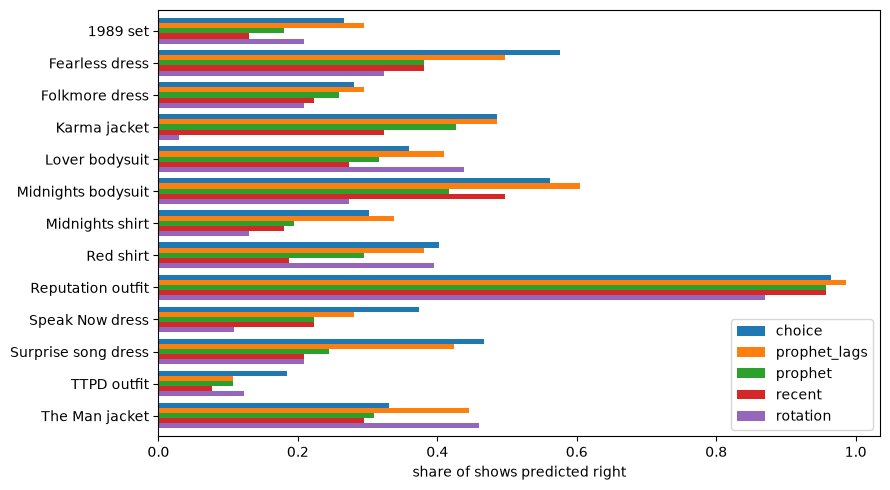

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
cols = [m for m in ["choice", "prophet_lags", "prophet", "recent", "rotation"] if m in accuracy]
accuracy.drop(index=[c for c in accuracy.index if c.startswith("Surprise song (")])[cols].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("share of shows predicted right"); ax.set_ylabel(""); ax.invert_yaxis()
ax.legend(loc="lower right"); plt.tight_layout()

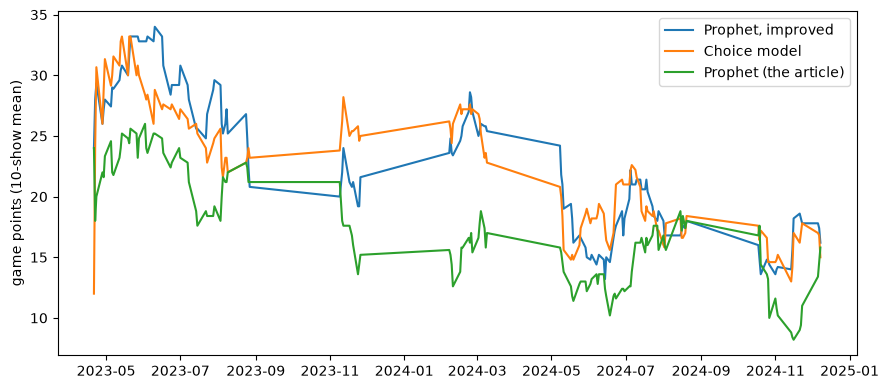

In [10]:
# points per show over the tour (rolling mean of 10 shows)
per_show = pd.DataFrame({e.name: B.game_points(results, e.outfit_method, e.song_method)
                         for e in entries.itertuples()})
dates = tour.shows.date[per_show.index]
fig, ax = plt.subplots(figsize=(9, 4))
for col in per_show.columns[:3]:
    ax.plot(dates, per_show[col].rolling(10, min_periods=1).mean(), label=col)
ax.set_ylabel("game points (10-show mean)"); ax.legend(); plt.tight_layout()

### Surprise songs

Close to luck for every method: ~150 songs she hasn't played yet and two (sometimes more, in mashups) per
instrument each night.

In [11]:
s = results[results.category.str.startswith("Surprise song (")]
s.pivot_table(index="category", columns="method", values="points", aggfunc="mean").div(data.SONG_POINTS).round(3)

method,choice,most_played,random
category,,,
Surprise song (guitar),0.022,0.007,0.015
Surprise song (piano),0.029,0.050,0.011


## Save

The metrics go to `results/` (in git); the per-show tables for the API go to `artifacts/lookup/` (not in git: upload them to the bucket the site mounts).

In [12]:
RESULTS_DIR.mkdir(exist_ok=True)
entries.drop(columns="description").round(3).to_csv(RESULTS_DIR / "entries.csv", index=False)
accuracy.round(3).to_csv(RESULTS_DIR / "accuracy_by_category.csv")
lookup.write(ARTIFACTS_DIR / "lookup", lookup.build(tour, results))
print("saved", sorted(p.name for p in (ARTIFACTS_DIR / "lookup").iterdir()))

saved ['entries.csv', 'picks.csv', 'shows.csv']
